# 04 — CUDA YOLOv8n WBC training

**Purpose:** Run one CUDA smoke epoch, verify checkpoints, then run or resume full transfer learning on Windows.

**Required inputs:** Valid processed data, `Python (leukemia-yolo)` kernel, CUDA-enabled PyTorch and `yolov8n.pt` download/cache access.

**Saved outputs:** Timestamped runs in `outputs/checkpoints/` with best.pt, last.pt, results.csv, results.png, logs and effective config.

## 1. Load the central configuration

The root is found from the notebook location or the installed package. Set `LEUKEMIA_YOLO_CONFIG` only for synthetic smoke tests or an alternate config.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "config.py").is_file():
        sys.path.insert(0, str(candidate))
        break
from src.config import load_config, ensure_outputs
cfg = load_config()
out = ensure_outputs(cfg)
os.chdir(cfg["root"])
print("Project root:", cfg["root"])
print("Configuration:", cfg["config_path"])

Project root: D:\CellCancer\leukemia-yolo
Configuration: D:\CellCancer\leukemia-yolo\config.local.yaml


## A. Check GPU and dataset readiness

CUDA failure stops this notebook. System RAM and dedicated NVIDIA VRAM are separate resources.

In [2]:
from src.training import training_readiness, stream_training, checkpoint_for_run, results_table, progress_columns
from src.environment import nvidia_smi
from IPython.display import display, Image as IPImage
import pandas as pd
ready = training_readiness(cfg)
display(pd.DataFrame([{"setting": k, "value": str(v)} for k,v in ready.items()]))
print("nvidia-smi:", nvidia_smi())

,setting,value
0,dataset,D:\CellCancer\leukemia-yolo\data\processed\BCC...
1,train_images,205
2,fingerprint,b23109fc103cd150a2a2207fe94316e03ebef4717e2081...
3,gpu,{'gpu_name': 'NVIDIA GeForce RTX 3050 Ti Lapto...
4,model,yolov8n.pt
5,epochs,50
6,imgsz,640
7,batch,0.75
8,amp,True
9,workers,2


nvidia-smi: {'available': True, 'query': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU, 566.07, 4096, 3884, 0'}


## B. Load pretrained detection checkpoint

This must be the YOLOv8n **detection** checkpoint. First use may download it from Ultralytics.

In [3]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
assert model.task == "detect", f"Unexpected task: {model.task}"
print("PASS — pretrained object detector loaded:", cfg["model"])

PASS — pretrained object detector loaded: yolov8n.pt


## C. Show effective plan

Default batch 0.75 asks Ultralytics AutoBatch to target a fraction of GPU memory. Automatic disk caching requires Windows to identify an SSD and enough free space; unknown media type disables cache.

In [4]:
from src.training import choose_cache
plan = {"epochs": cfg["epochs"], "imgsz": cfg["imgsz"], "batch": cfg["batch"],
        "device": cfg["device"], "amp": cfg["amp"], "workers": cfg["workers"],
        "patience": cfg["patience"], "seed": cfg["seed"], "plots": True,
        "save": True, "save_period": 5, "cache": choose_cache(cfg)}
display(pd.DataFrame(plan.items(), columns=["setting", "value"]))
print("If Windows DataLoader stalls, set workers: 0 in config.local.yaml and start a new run.")

,setting,value
0,epochs,50
1,imgsz,640
2,batch,0.75
3,device,0
4,amp,True
5,workers,2
6,patience,15
7,seed,42
8,plots,True
9,save,True


If Windows DataLoader stalls, set workers: 0 in config.local.yaml and start a new run.


## D. Run one smoke epoch

Training runs in a Windows-safe child process through `sys.executable`; its stdout and stderr stream here and to a log. Set `RESUME_LAST` to an unfinished last.pt to skip a new smoke run.

In [5]:
RESUME_LAST = None  # Optional Path(".../weights/last.pt") from an interrupted main run.
ALLOW_BATCH_FALLBACK = True  # Logged AutoBatch/OOM retry at batch=4 in a NEW run; failed run is preserved.
smoke_run = None
if RESUME_LAST is None:
    smoke_run = stream_training(cfg, kind="smoke", allow_batch_fallback=ALLOW_BATCH_FALLBACK)
    print("Smoke run:", smoke_run)
else:
    RESUME_LAST = Path(RESUME_LAST).expanduser().resolve()
    print("Resuming existing main run from", RESUME_LAST)

RUN_START=D:\CellCancer\leukemia-yolo\outputs\checkpoints\smoke_20261013T085839Z_c22c86cf
Ultralytics 8.4.176  Python-3.11.17 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.75, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\CellCancer\leukemia-yolo\data\processed\BCCD_YOLO\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, m

## E. Verify smoke checkpoint

A completed one-epoch CUDA run, loadable last.pt and results.csv are required before main training.

In [6]:
if smoke_run:
    smoke_last = checkpoint_for_run(smoke_run, "last.pt")
    smoke_model = YOLO(str(smoke_last))
    assert smoke_model.task == "detect" and len(results_table(smoke_run)) >= 1
    print("PASS — CUDA smoke training and checkpoint load succeeded:", smoke_last)
else:
    assert RESUME_LAST.is_file()
    print("PASS — existing last.pt selected for resume")

PASS — CUDA smoke training and checkpoint load succeeded: D:\CellCancer\leukemia-yolo\outputs\checkpoints\smoke_20261013T085839Z_c22c86cf\weights\last.pt


## F. Train or resume main experiment

The main run requires the completed smoke run. Stopping leaves last.pt; resume by setting `RESUME_LAST` above. Reruns use new timestamped directories.

In [7]:
main_run = stream_training(cfg, kind="main", smoke_run=smoke_run, resume=RESUME_LAST,
                           allow_batch_fallback=ALLOW_BATCH_FALLBACK)
print("Main run:", main_run)

RUN_START=D:\CellCancer\leukemia-yolo\outputs\checkpoints\main_20261013T090007Z_a25a7934
Ultralytics 8.4.176  Python-3.11.17 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.75, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\CellCancer\leukemia-yolo\data\processed\BCCD_YOLO\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, m

## G. Review saved training outputs

A completed run must contain both checkpoints, CSV, plot and metadata.

{'kind': 'main',
 'status': 'completed',
 'dataset_fingerprint': 'b23109fc103cd150a2a2207fe94316e03ebef4717e2081f4095a4b897bf41e10',
 'pretrained_weights': 'yolov8n.pt',
 'started_utc': '2026-10-13T09:00:07.238611+00:00',
 'smoke_run': 'D:\\CellCancer\\leukemia-yolo\\outputs\\checkpoints\\smoke_20261013T085839Z_c22c86cf',
 'effective_config': {'data': 'D:\\CellCancer\\leukemia-yolo\\data\\processed\\BCCD_YOLO\\data.yaml',
  'epochs': 50,
  'imgsz': 640,
  'batch': 0.75,
  'device': 0,
  'amp': True,
  'workers': 2,
  'patience': 15,
  'seed': 42,
  'plots': True,
  'save': True,
  'save_period': 5,
  'cache': 'disk',
  'project': 'D:\\CellCancer\\leukemia-yolo\\outputs\\checkpoints',
  'name': 'main_20261013T090007Z_a25a7934',
  'exist_ok': True},
 'gpu_start': {'gpu_name': 'NVIDIA GeForce RTX 3050 Ti Laptop GPU',
  'dedicated_vram_gib': 3.99951171875,
  'available_vram_gib': 3.212597656995058,
  'compute_capability': '8.6',
  'torch_version': '2.14.1+cu126',
  'torch_cuda_version': '1

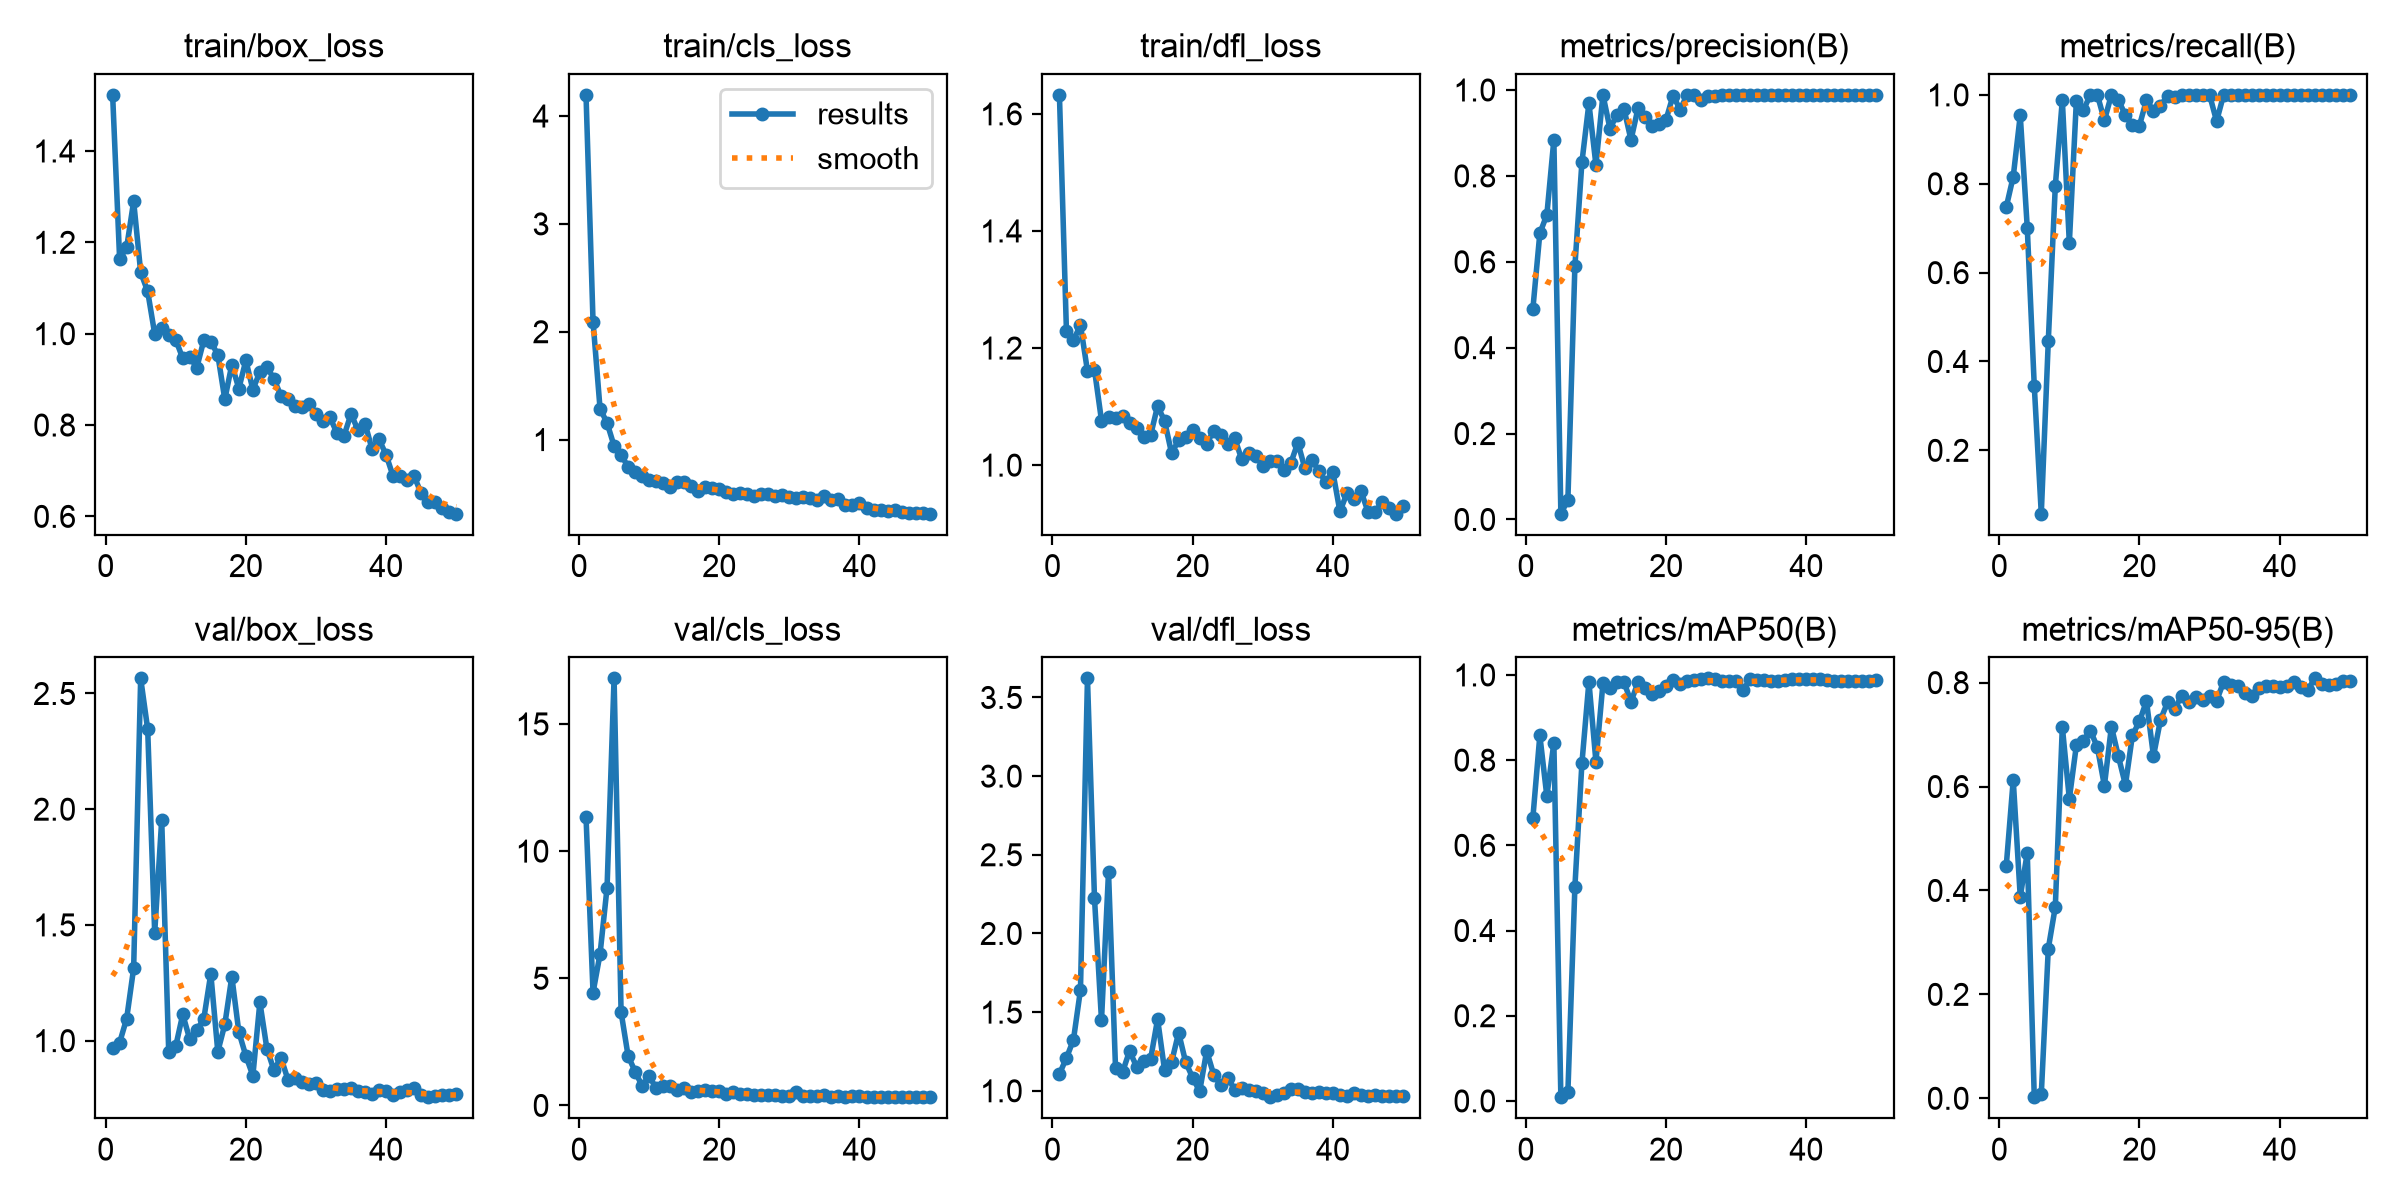

In [8]:
from src.config import read_json
metadata = read_json(main_run / "run_metadata.json")
for name in ("weights/best.pt", "weights/last.pt", "results.csv", "results.png", "effective_training_config.json"):
    assert (main_run / name).is_file(), name
display(metadata)
display(IPImage(filename=str(main_run / "results.png")))

## H. GPU utilization and peak VRAM

These values describe this run; 100% utilization is neither required nor promised.

In [9]:
display(pd.DataFrame([{"GPU": metadata["gpu_start"]["gpu_name"],
                         "peak allocated GiB": metadata.get("gpu_peak_allocated_gib"),
                         "actual batch": metadata.get("actual_batch"),
                         "nvidia-smi at end": metadata.get("nvidia_smi_end")}]))

,GPU,peak allocated GiB,actual batch,nvidia-smi at end
0,NVIDIA GeForce RTX 3050 Ti Laptop GPU,1.84156,16,"{'available': True, 'query': 'NVIDIA GeForce R..."


## I. Latest epoch progress

The CSV reader tolerates a partially written last row during a running experiment.

In [10]:
progress = progress_columns(results_table(main_run))
display(progress.tail(10))
assert not progress.empty and metadata["completed_epochs"] > 0

,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),time
40,41,0.68791,0.36154,0.92088,0.98776,1.0,0.98955,0.79435,167.479
41,42,0.68841,0.34966,0.95176,0.98784,1.0,0.98932,0.80113,171.191
42,43,0.67915,0.34404,0.94142,0.98788,1.0,0.98705,0.79190,174.801
43,44,0.68802,0.33745,0.95570,0.98804,1.0,0.98568,0.78563,178.437
44,45,0.65042,0.34432,0.92058,0.98791,1.0,0.98625,0.80814,181.970
45,46,0.63114,0.32665,0.91961,0.98795,1.0,0.98659,0.79737,185.595
46,47,0.63133,0.31899,0.93654,0.98795,1.0,0.98580,0.79610,189.134
47,48,0.61926,0.31558,0.92746,0.98793,1.0,0.98614,0.79774,192.614
48,49,0.60975,0.32060,0.91703,0.98788,1.0,0.98670,0.80264,196.167
49,50,0.60586,0.31286,0.93029,0.98782,1.0,0.98727,0.80396,199.744


## J. Load best checkpoint and finish

This checkpoint is used for later held-out evaluation and inference.

In [11]:
best_path = checkpoint_for_run(main_run)
best_model = YOLO(str(best_path))
assert best_model.task == "detect"
print("PASS — completed CUDA training. Best checkpoint:", best_path)
print("Validation metrics are in results.csv; held-out test metrics are produced only by notebook 05.")

PASS — completed CUDA training. Best checkpoint: D:\CellCancer\leukemia-yolo\outputs\checkpoints\main_20261013T090007Z_a25a7934\weights\best.pt
Validation metrics are in results.csv; held-out test metrics are produced only by notebook 05.


## Next notebook

Open **05_Model_Evaluation.ipynb**. Never tune hyperparameters from its held-out test results.